# La Liga Match Prediction

Predicting La Liga match outcomes (home win / draw / away win) and the most likely scoreline from historical match data, Elo ratings and scraped xG, benchmarked against bookmaker odds.

## Imports


In [1]:
# Standard library
import sys  # lets us edit the module search path (next steps)
from pathlib import Path  # OS-independent paths, no hard-coded C:\... strings

# Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

## Notebook setup

Reload edited `src/` modules automatically and make the repo root importable, so reusable code can live in `src/` instead of the notebook.


In [2]:
%load_ext autoreload
# Mode 2 = reload all modules (except excluded ones) before running each cell, so
# edits to src/*.py take effect without a kernel restart
%autoreload 2

In [3]:
# Walk up from the working directory (notebooks/ in VS Code) until we reach the
# folder that contains environment.yml: that is the repo root
REPO_ROOT = next(
    folder
    for folder in [Path.cwd(), *Path.cwd().parents]
    if (folder / "environment.yml").exists()
)

# Put the repo root first on the import path so `from src... import ...` works.
# The check avoids adding a duplicate entry every time this cell is re-run.
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

print(f"Repo root: {REPO_ROOT}")

Repo root: c:\laliga-match-prediction


In [4]:
from src.cleaning import (
    add_season_columns,
    format_season,
    missing_pct_by_group,
    missing_value_summary,
)
from src.team_names import MATCHES_NAME_FIXES

In [5]:
# One chart style for the whole notebook
sns.set_theme(
    style="whitegrid",
    rc={
        "axes.edgecolor": "#c3c2b7",
        "grid.color": "#e1e0d9",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.titleweight": "bold",
        "figure.dpi": 110,
    },
)

## Config / constants

All paths are built from `REPO_ROOT`, so the notebook runs from any clone without editing. `RANDOM_STATE` is the single seed used everywhere randomness appears, so results are reproducible.


In [6]:
# Data folders (raw = downloaded/scraped and never modified, processed = our outputs)
DATA_DIR = REPO_ROOT / "data"
RAW_DIR = DATA_DIR / "raw"
PROCESSED_DIR = DATA_DIR / "processed"

# Deliverables: Excel workbook, saved figures, predictions
OUTPUTS_DIR = REPO_ROOT / "outputs"

# One seed for every train/test split, CV fold and model, for reproducible results
RANDOM_STATE = 42

# The columns that identify one match: a team can't host the same opponent twice on one day, so this combination must be unique
MATCH_KEY = ["Division", "MatchDate", "HomeTeam", "AwayTeam"]

# Divisions we use: La Liga, plus Segunda for promoted teams' pre-La Liga history
LALIGA_DIVISION = "SP1"
SEGUNDA_DIVISION = "SP2"
SPANISH_DIVISIONS = [LALIGA_DIVISION, SEGUNDA_DIVISION]

# The two columns holding team names in Matches.csv
TEAM_COLUMNS = ["HomeTeam", "AwayTeam"]

# Full-time goals: The targets of the scoreline model
FULL_TIME_GOAL_COLUMNS = ["FTHome", "FTAway"]

# Last fully played season: 2026/27 is in progress, so it is excluded from season-level EDA and kept for the prediction demo
LAST_COMPLETE_SEASON = 2025

# Saved charts for the README and the pitch
FIGURES_DIR = OUTPUTS_DIR / "figures"

# One fixed color per result, reused in every chart
RESULT_ORDER = ["H", "D", "A"]
RESULT_LABELS = {"H": "Home win", "D": "Draw", "A": "Away win"}
RESULT_COLORS = {"H": "#2a78d6", "D": "#1baf7a", "A": "#eb6834"}

## Load data

Raw files from [xgabora/Club-Football-Match-Data](https://github.com/xgabora/Club-Football-Match-Data) (MIT license), downloaded manually into `data/raw/`. Loaded as-is: filtering to La Liga and cleaning happen in later sections.


In [7]:
# parse_dates turns the date text ("2000-07-28") into real datetimes, so we can
# sort, filter by date range and derive seasons. MatchTime is read as text
# explicitly because it is empty in older seasons (see note below)
matches = pd.read_csv(
    RAW_DIR / "Matches.csv", parse_dates=["MatchDate"], dtype={"MatchTime": str}
)

elo = pd.read_csv(RAW_DIR / "EloRatings.csv", parse_dates=["date"])

print(f"matches: {matches.shape}, elo: {elo.shape}")

matches: (238858, 48), elo: (273972, 4)


## Inspect / EDA

## Data profile

Before cleaning, check what we actually have: column types, missing values, duplicates and category counts. Every data-quality issue found here is listed and handled in _Clean / Preprocess_.


In [8]:
matches.info(verbose=True, show_counts=True)

<class 'pandas.DataFrame'>
RangeIndex: 238858 entries, 0 to 238857
Data columns (total 48 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   Division     238858 non-null  str           
 1   MatchDate    238858 non-null  datetime64[us]
 2   MatchTime    107373 non-null  str           
 3   HomeTeam     238858 non-null  str           
 4   AwayTeam     238858 non-null  str           
 5   HomeElo      149898 non-null  float64       
 6   AwayElo      149829 non-null  float64       
 7   Form3Home    237334 non-null  float64       
 8   Form5Home    237323 non-null  float64       
 9   Form3Away    237335 non-null  float64       
 10  Form5Away    237324 non-null  float64       
 11  FTHome       238854 non-null  float64       
 12  FTAway       238854 non-null  float64       
 13  FTResult     238854 non-null  str           
 14  HTHome       184278 non-null  float64       
 15  HTAway       184278 non-null  float64       


In [9]:
missing_match = missing_value_summary(matches)
missing_match

,missing_count,missing_pct
MatchTime,131485,55.0
C_LTA,126256,52.9
C_PHB,126256,52.9
C_HTB,126256,52.9
C_LTH,126256,52.9
C_VAD,126256,52.9
C_VHD,126256,52.9
HomeTarget,117181,49.1
AwayTarget,117178,49.1
HomeFouls,117137,49.0


In [10]:
missing_elo = missing_value_summary(elo)
missing_elo

,missing_count,missing_pct


In [11]:
# Exact duplicates: Every column identical
n_exact_duplicates = matches.duplicated().sum()

# Duplicate matches: Same fixture recorded twice, even if a stat differs
n_key_duplicates = matches.duplicated(subset=MATCH_KEY).sum()

print(
    f"Matches: {n_exact_duplicates} exact duplicate rows, {n_key_duplicates} duplicate matches."
)

Matches: 0 exact duplicate rows, 0 duplicate matches.


In [12]:
# Each club has at most one rating per date, so (date, club) identifies a row
n_exact_duplicates_elo = elo.duplicated().sum()
n_key_duplicates_elo = elo.duplicated(subset=["date", "club"]).sum()

print(
    f"Elo: {n_exact_duplicates_elo} exact duplicate rows, {n_key_duplicates_elo} duplicate (date, club) rows."
)

Elo: 0 exact duplicate rows, 0 duplicate (date, club) rows.


In [13]:
division_counts = matches["Division"].value_counts()

print(f"{len(division_counts)} division")
division_counts[SPANISH_DIVISIONS]  # La Liga and Segunda Division

38 division


Division
SP1     9419
SP2    10992
Name: count, dtype: int64

In [14]:
# Result Distribution:
results = matches["FTResult"]
result_counts = pd.DataFrame(
    {
        "count": results.value_counts(dropna=False),
        "pct": (results.value_counts(normalize=True, dropna=False) * 100).round(1),
    }
)

result_counts

,count,pct
FTResult,,
H,106451,44.6
A,69101,28.9
D,63302,26.5
NaN,4,0.0


In [15]:
# Which matches have no final result, and are any of them in La Liga / Segunda?
matches.loc[matches["FTResult"].isna(), MATCH_KEY + ["FTHome", "OddHome"]]

,Division,MatchDate,HomeTeam,AwayTeam,FTHome,OddHome
112580,G1,2015-05-10,Niki Volos,OFI,NaN,NaN
130377,BRA,2016-11-12,Chapecoense-SC,Atletico-MG,NaN,2.85
159189,G1,2019-03-17,Panathinaikos,Olympiakos,NaN,5.25
233555,F2,2025-12-05,Bastia,Red Star,NaN,2.50


### Conclusion

- **No duplicates in either file**, so there's no deduplication step in cleaning.
- **Home advantage is visible already.** Across all leagues, home teams win 44.6% of matches, while away teams 28.9%. We will check whether La Liga matches that in EDA.
- **Draws are 26.5%.** Could come in handy later.
- **The 4 missing results don't affect us.** The La Liga filter removes them.


### Season structure (La Liga and Segunda)

From here on we only need Spanish matches. La Liga (`SP1`) is what we predict, and Segunda (`SP2`) gives promoted teams a match history before they reach La Liga.
A season runs from August to May, so we derive a `Season` label from the date (cutoff 10 August, explained in `src/cleaning.py`).


In [16]:
# Keep only La Liga and Segunda (the other 36 divisions are out of scope)
spanish_matches = matches[matches["Division"].isin(SPANISH_DIVISIONS)]

print(f"Spanish Matches: {spanish_matches.shape}")

Spanish Matches: (20411, 48)


In [17]:
spanish_matches = add_season_columns(spanish_matches)
spanish_matches[["MatchDate", "SeasonStart", "Season"]].sample(
    5, random_state=RANDOM_STATE
)

,MatchDate,SeasonStart,Season
123238,2016-04-02,2015,2015/16
190821,2021-12-18,2021,2021/22
28467,2005-09-17,2005,2005/06
47848,2008-04-27,2007,2007/08
174517,2020-10-03,2020,2020/21


In [18]:
# First / Last match date and match count per division and season.
# A complete La Liga season has 380 matches (20 teams x 19 opponents x home and away)
season_ranges = (
    spanish_matches.groupby(["Division", "Season"])["MatchDate"]
    .agg(first_match="min", last_match="max", n_matches="count")
    .reset_index()
)
season_ranges

,Division,Season,first_match,last_match,n_matches
0,SP1,2000/01,2000-09-09,2001-06-17,380
1,SP1,2001/02,2001-08-25,2002-05-11,380
2,SP1,2002/03,2002-08-31,2003-06-22,380
3,SP1,2003/04,2003-08-30,2004-05-23,380
4,SP1,2004/05,2004-08-28,2005-05-29,268
5,SP1,2005/06,2005-08-27,2006-05-20,380
6,SP1,2007/08,2007-08-25,2008-05-18,380
7,SP1,2008/09,2008-08-30,2009-05-31,380
8,SP1,2009/10,2009-08-29,2010-05-16,380
9,SP1,2010/11,2010-08-28,2011-05-21,380


### Data-Quality issues to flag

- **2006/07 is missing entirely:** No `SP1` or `SP2` rows at all. 2005/06 jumps straight to 2007/08.
- **La Liga 2004/05 is incomplete:** 268 of 380 matches.
- **Segunda's early seasons are incomplete:** 2001/02: 414, 2002/03: 239, 2003/04: 158 and 2007/08: 446 (of 462).
- **2026/27 is in progress:** 31 La Liga matches, up to 2026-09-03. This is our demo season, not training data.

These will matter in feature engineering. A rolling "last 5 matches" window will silently jump across the missing 2006/07 season, and promoted-team detection ("in La Liga this season but not last season") breaks around a missing season.


### Missing values by season

Which seasons actually have each kind of data? This decides which features we can build and over which seasons. Only home-side columns are shown: Every away-side column (e.g `AwayShots`) has the same gaps as its home counterpart.


In [19]:
laliga = spanish_matches[spanish_matches["Division"] == LALIGA_DIVISION]
segunda = spanish_matches[spanish_matches["Division"] == SEGUNDA_DIVISION]

print(f"La Liga: {laliga.shape}, Segunda: {segunda.shape}")

La Liga: (9419, 50), Segunda: (10992, 50)


In [20]:
# Overall La Liga missingness now on our real scope
missing_value_summary(laliga)

,missing_count,missing_pct
MatchTime,6728,71.4
C_PHB,2200,23.4
C_LTA,2200,23.4
C_LTH,2200,23.4
C_HTB,2200,23.4
C_VHD,2200,23.4
C_VAD,2200,23.4
Over25,1789,19.0
MaxUnder25,1789,19.0
Under25,1789,19.0


In [21]:
# One representative column per data type: ratings / form, half-time score, match stats, bookmaker odds, kickoff time and the cluster columns
PROFILE_COLUMNS = [
    "HomeElo",
    "Form5Home",
    "HTHome",
    "HomeShots",
    "HomeTarget",
    "HomeCorners",
    "HomeFouls",
    "HomeYellow",
    "OddHome",
    "MaxHome",
    "Over25",
    "MatchTime",
    "C_LTH",
]

# Color scale fixed at 0 - 100% so the shading means the same thing in every table
missing_pct_by_group(laliga, "Season", PROFILE_COLUMNS).style.background_gradient(
    cmap="Reds", vmin=0, vmax=100
).format("{:.0f}")

,HomeElo,Form5Home,HTHome,HomeShots,HomeTarget,HomeCorners,HomeFouls,HomeYellow,OddHome,MaxHome,Over25,MatchTime,C_LTH
Season,,,,,,,,,,,,,
2000/01,0,0,0,100,100,100,100,100,1,100,100,100,100
2001/02,0,0,0,100,100,100,100,100,21,100,100,100,100
2002/03,0,0,0,100,100,100,100,100,0,100,100,100,100
2003/04,0,0,0,100,100,100,100,100,1,100,100,100,100
2004/05,0,0,0,100,100,100,100,100,0,100,100,100,100
2005/06,0,0,0,0,0,0,0,0,0,0,0,100,0
2007/08,0,0,0,0,0,0,0,0,0,0,0,100,0
2008/09,0,0,0,0,0,0,0,0,0,0,0,100,0
2009/10,0,0,0,0,0,0,0,0,0,0,0,100,0


In [22]:
missing_pct_by_group(segunda, "Season", PROFILE_COLUMNS).style.background_gradient(
    cmap="Reds", vmin=0, vmax=100
).format("{:.0f}")

,HomeElo,Form5Home,HTHome,HomeShots,HomeTarget,HomeCorners,HomeFouls,HomeYellow,OddHome,MaxHome,Over25,MatchTime,C_LTH
Season,,,,,,,,,,,,,
2000/01,0,0,0,100,100,100,100,100,26,100,100,100,100
2001/02,4,0,0,100,100,100,100,100,27,100,100,100,100
2002/03,0,0,0,100,100,100,100,100,7,100,100,100,100
2003/04,0,0,0,100,100,100,100,100,31,100,100,100,100
2004/05,4,0,0,100,100,100,100,100,10,100,100,100,100
2005/06,4,0,0,100,100,100,100,100,0,0,0,100,100
2007/08,4,0,0,100,100,100,100,100,0,0,0,100,100
2008/09,4,0,0,100,100,100,100,100,0,2,2,100,100
2009/10,4,0,0,100,100,100,100,100,0,0,0,100,100


### Findings: missing values by season

**La Liga**

- **The core pre-match data is complete in every season.** `HomeElo`/ `AwayElo`, the `Form*` columns, and full-time and half-time scores have no missing values at all, which is why they don't appear in `missing_value_summary(laliga)`.
- **Match stats only exist from 2005/06.** Shots, shots on target, corners, fouls and cards are 100% missing for 2000/01–2004/05 and complete afterwards. That's 1,788 matches (19.0%). Four full seasons of 380 plus the incomplete 2004/05 (268). The `Max*` and over / under odds follow the same pattern.
- **1X2 bookmaker odds are missing for 90 matches (1.0%)**, 80 of them in 2001/02. The bookmaker benchmark can't be computed for those matches, but the 2025/26 test season is complete.
- **Kickoff time (`MatchTime`) is missing until 2018/19** (71.4% overall). We don't use it, so no action is needed.

**Segunda Division**

- **Match stats only exist from 2017/18.** Before that, promoted teams have goals, Elo and form history from Segunda, but no shot or corner history.
- **Elo has small, regular gaps.** 4.5% in a season is exactly one team out of 22 without an Elo rating (9.1% is two). The teams are Gimnastic, Extremadura UD and Andorra. None of them appears in La Liga in our data, so this doesn't affect any team we predict.

**What this means for modeling**

- Features from Elo, form and goals can use every season.
- Features from match stats (shots, corners, cards) only work from 2005/06. With 2006/07 missing from the data, **2007/08 onward** is the first unbroken stretch where every feature is available. That makes it a candidate training window, to be decided in feature engineering.
- For promoted teams, shot-based rolling features will lack second-division history before 2017/18, so they'll need a documented fallback.


## Clean / Preprocess

Turn the Spanish subset into a clean, analysis ready table.
Drop unusable columns, fix team name inconsistencies, set correct types.


In [23]:
# C_* cluster columns may be derived from in-match stats and are blank for 2025/26-2026/27. MatchTime is 71% missing and no feature uses it
CLUSTER_COLUMNS = [col for col in spanish_matches.columns if col.startswith("C_")]
COLUMNS_TO_DROP = CLUSTER_COLUMNS + ["MatchTime"]

spanish_clean = spanish_matches.drop(columns=COLUMNS_TO_DROP)

print(f"Dropped: {COLUMNS_TO_DROP}")
print(f"{spanish_matches.shape} --> {spanish_clean.shape}")

Dropped: ['C_LTH', 'C_LTA', 'C_VHD', 'C_VAD', 'C_HTB', 'C_PHB', 'MatchTime']
(20411, 50) --> (20411, 43)


In [24]:
# Apply the same fixes to both team columns: {column: {old_name: new_name}}
spanish_clean = spanish_clean.replace({col: MATCHES_NAME_FIXES for col in TEAM_COLUMNS})

# Check the club now has one name covering both of its Segunda seasons
is_leonesa = (spanish_clean[TEAM_COLUMNS] == "Cultural Leonesa").any(axis=1)
spanish_clean.loc[is_leonesa].groupby("Season").size()

Season
2017/18    42
2025/26    42
dtype: int64

In [25]:
# FT goals are complete and whole numbers, so store them as real integers.
# astype("int64") raises an error if a NaN is present, so this cell also acts as a check that no full-time score is missing
spanish_clean = spanish_clean.astype({col: "int64" for col in FULL_TIME_GOAL_COLUMNS})

spanish_clean[FULL_TIME_GOAL_COLUMNS + ["HTHome", "HomeShots"]].head(3)

,FTHome,FTAway,HTHome,HomeShots
374,1,0,1.0,NaN
375,0,0,0.0,NaN
376,0,0,0.0,NaN


**Dtype decision:** Full-time goals are complete in the Spanish data, so they are stored as `int64`. Half-time goals and match stats still contain missing values (pre-2005/06 stats, 22 Segunda half-time scores), so they stay `float64` with `NaN`. Pandas' nullable `Int64` would also work, but it would mix two missing-value markers (`NaN` and `pd.NA`, which follow different comparison rules) in one table, for a purely cosmetic gain. These columns only feed rolling averages, which are floats anyway.


### Data invariants

Assumptions the feature engineering and models rely on, checked explicitly so the notebook stops loudly if a future data update breaks one.


In [26]:
# One row per team per match: Each match appears twice, once from each side.
# This view makes per-team checks simple, and it's the same shape we'll use for
# the rolling team features later
CONTEXT_COLUMNS = ["Season", "Division", "MatchDate"]

team_appearances = pd.concat(
    [
        spanish_clean[CONTEXT_COLUMNS + ["HomeTeam"]].rename(
            columns={"HomeTeam": "Team"}
        ),
        spanish_clean[CONTEXT_COLUMNS + ["AwayTeam"]].rename(
            columns={"AwayTeam": "Team"}
        ),
    ],
    ignore_index=True,
)

print(team_appearances.shape)

(40822, 4)


In [27]:
# What FTResult should be according to the goals: np.select checks the conditions in order and picks the matching label, "D" if none match
expected_result = np.select(
    [
        spanish_clean["FTHome"] > spanish_clean["FTAway"],
        spanish_clean["FTHome"] < spanish_clean["FTAway"],
    ],
    ["H", "A"],
    default="D",
)

team_plays_twice_a_day = team_appearances.duplicated(subset=["Team", "MatchDate"])
team_division_seasons = team_appearances.drop_duplicates(
    subset=["Season", "Division", "Team"]
)
team_in_two_divisions = team_division_seasons.duplicated(subset=["Season", "Team"])

assert (spanish_clean["FTResult"] == expected_result).all(), (
    "FTResult disagrees with goals"
)
assert spanish_clean["MatchDate"].is_monotonic_increasing, "Matches not sorted by date"
assert (spanish_clean["HomeTeam"] != spanish_clean["AwayTeam"]).all(), (
    "A team plays itself"
)
assert not team_plays_twice_a_day.any(), "A team plays twice on one day"
assert not team_in_two_divisions.any(), "A team is in two divisions in one season"

# An assert stops the notebook with a clear message the moment an assumption fails, instead of letting a wrong number reach the model. They all hold today. The point is to protect against a re-downloaded dataset or a future name-mapping mistake.
print("All invariants hold")

All invariants hold


### Save the cleaned data

Checkpoint the cleaned La Liga + Segunda table to `data/processed/`, so later steps can start from it.


In [28]:
# The old index labels were positions in the 38-league file which is meaningless now, and a trap if a later concat / merge aligned on them. drop=True discards them instead of keeping them as a column
spanish_clean = spanish_clean.reset_index(drop=True)
spanish_clean.head(3)

,Division,MatchDate,HomeTeam,AwayTeam,HomeElo,AwayElo,Form3Home,Form5Home,Form3Away,Form5Away,...,MaxAway,Over25,Under25,MaxOver25,MaxUnder25,HandiSize,HandiHome,HandiAway,SeasonStart,Season
0,SP2,2000-09-02,Albacete,Tenerife,1579.53,1593.38,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2000,2000/01
1,SP2,2000-09-02,Getafe,Cordoba,1503.48,1540.89,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2000,2000/01
2,SP2,2000-09-02,Lleida,Eibar,1607.34,1577.07,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2000,2000/01


In [29]:
# Git doesn't track empty folders, so data/processed/ won't exist in a fresh clone. Create it if missing (exist_ok=True means no error if it is already there)

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

clean_path = PROCESSED_DIR / "spanish_matches_clean.csv"
spanish_clean.to_csv(clean_path, index=False)

print(f"Saved {spanish_clean.shape} to {clean_path.relative_to(REPO_ROOT)}")

Saved (20411, 43) to data\processed\spanish_matches_clean.csv


## Exploratory Data Analysis (EDA)

La Liga only (`SP1`), complete seasons 2000/01-2025/26. The in-progress 2026/27 season is a too small sample for season-level patterns.


In [30]:
laliga_clean = spanish_clean[spanish_clean["Division"] == LALIGA_DIVISION]
laliga_complete = laliga_clean[laliga_clean["SeasonStart"] <= LAST_COMPLETE_SEASON]

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
print(f"La Liga: {laliga_clean.shape}, complete seasons: {laliga_complete.shape}")

La Liga: (9419, 43), complete seasons: (9388, 43)


In [31]:
# Share of home wins / draws / away wins per season (each row sums to 100%).
# reindex adds an empty row for 2006/07, so the chart shows a gap instead of silently joining 2005/06 to 2007/08
all_seasons = range(
    laliga_complete["SeasonStart"].min(), laliga_complete["SeasonStart"].max() + 1
)

result_share_by_season = (
    pd.crosstab(
        laliga_complete["SeasonStart"], laliga_complete["FTResult"], normalize="index"
    )[RESULT_ORDER]
    .mul(100)
    .reindex(all_seasons)
)

result_share_by_season.round(1)  # Table version of the chart below

FTResult,H,D,A
SeasonStart,,,
2000,52.4,26.1,21.6
2001,48.9,26.6,24.5
2002,46.3,27.6,26.1
2003,45.3,25.0,29.7
2004,51.1,26.9,22.0
2005,42.6,27.6,29.7
2006,NaN,NaN,NaN
2007,47.9,22.9,29.2
2008,48.4,21.8,29.7


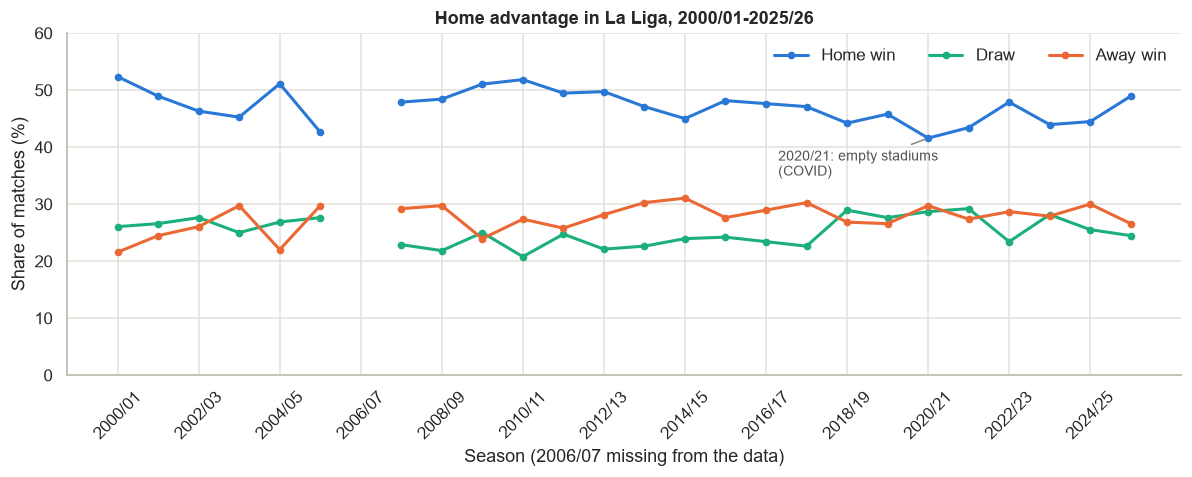

In [32]:
fig, ax = plt.subplots(figsize=(11, 4.5))

for result in RESULT_ORDER:
    ax.plot(
        result_share_by_season.index,
        result_share_by_season[result],
        color=RESULT_COLORS[result],
        linewidth=2,
        marker="o",
        markersize=4,
        label=RESULT_LABELS[result],
    )

# Label the one season played (almost entirely) without fans (COVID)
ax.annotate(
    "2020/21: empty stadiums\n(COVID)",
    xy=(2020, result_share_by_season.loc[2020, "H"]),
    xytext=(2016.3, 35),
    arrowprops={"arrowstyle": "-", "color": "#898781"},
    color="#52514e",
    fontsize=9,
)

tick_years = list(all_seasons)[::2]  # Every 2nd season, so labels don't collide
ax.set_xticks(tick_years, [format_season(year) for year in tick_years], rotation=45)
ax.set(
    title="Home advantage in La Liga, 2000/01-2025/26",
    xlabel="Season (2006/07 missing from the data)",
    ylabel="Share of matches (%)",
    ylim=(0, 60),
)
ax.legend(loc="upper right", frameon=False, ncols=3)

fig.tight_layout()
fig.savefig(FIGURES_DIR / "home_advantage_by_season.png")
plt.show()

In [33]:
# Overall result distribution across all complete seasons
(laliga_complete["FTResult"].value_counts(normalize=True)[RESULT_ORDER] * 100).round(1)

FTResult
H    47.2
D    25.2
A    27.7
Name: proportion, dtype: float64